# Tasks 2: PCA and Clustering of Daily Portfolio returns 
**Approach:** (a) PCA on the 25 portfolio rows, (b) hierarchical clustering on the PC scores, (c) K-Means on the PC scores, (d) test whether the clusters carry information about NBER recessions

## Introduction
**Goal.** Reduce the dimensionality of 25 daily portfolio return series with PCA, cluster the trading days (hierarchical and K-Means), and ask whether those clusters say anything about NBER recessions.

**Data.** `HW5Portfolio25.csv` has one row per trading day (July 1926 to February 2023, 25,438 usable days after dropping rows with missing values) and one column per portfolio (25 size/book-to-market sorted portfolios). Each *day* is an observation described by 25 returns. `HW5USREC.csv` holds the monthly NBER recession indicator (1 = recession, 0 = expansion).

Each part below has its settings and reasoning in markdown, the code (commented) beneath it, and a short "Results" paragraph after the output.

In [ ]:
import numpy as np # Import the necessary libraries 
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, roc_auc_score, roc_curve, confusion_matrix
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
SEED = 37 # Fixed random seed for reproducible results
PALETTE = plt.get_cmap("tab10").colors # One color per cluster 

In [ ]:
# Load the entire portfolio dataset (one row per trading day, 25 trading return columns)
data = pd.read_csv("HW5Portfolio25.csv")

dates = pd.to_datetime(data["Date"], format="%Y%m%d") # Convert the dates column to date format instead of ints
X = data.drop(columns="Date").apply(pd.to_numeric, errors="coerce") 

# Drop any day that has a missing value in any portfolio (PCA cannot handle NaNs)
valid_X = X.notna().all(axis=1)
X = X.loc[valid_X]
dates = dates.loc[valid_X]
print("Rows kept:", len(X), "| Portfolios:", X.shape[1], "|", dates.min().date(), "to", dates.max().date())

# Equal-weighted average return across 25 portfolios, a simple market measurement used later to describe or profile the clusters afterwards
market = pd.Series(X.mean(axis=1).to_numpy(), index=dates, name="market")

Rows kept: 25438 | Portfolios: 25 | 1926-07-01 to 2023-02-28


## (a) PCA
**Standardization:** all 25 series are daily returns in the same units, so I run PCA on the raw data. Standardizing would give each portfolio equal weight regardless of its volatility and discard the useful information about which portfolios drive the variation. 

**Number of components:** I look at the scree plot (where the curve flattens) and the cumulative variance, and keep the smallest number of PCs reaching 90% of variance.

In [3]:
pca_all = PCA().fit(X)
explained = pca_all.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_components = np.argmax(cumulative >= 0.90) + 1
print(f"Principal components for at least 90% variance: {n_components} (cumulative = {cumulative[n_components]:.4f})")
print(f"Variance explained by the first {n_components} PCs: {np.round(explained[:6], 4)}")

Principal components for at least 90% variance: 6 (cumulative = 0.9200)
Variance explained by the first 6 PCs: [0.6518 0.133  0.0525 0.0301 0.0252 0.0137]


**Results (a):** The first PC alone explains about 65% of the total variance, PC2 about 13%, and the next four 5.3%, 3.0%, 2.5% and 1.4%. Together the first **6 PCs explain about 90.6%** of the variance, so I keep 6. The scree plot has a sharp elbow at about PC3 and is nearly flat after PC6, so the elbow alone would suggest 3, and 6 is a more conservative choice that keeps over 90% of the information while cutting 25 dimensions to 6. Each day is now represented by its six PC scores, which are the input to (b) and (c).

*Why 90% and not the elbow:* PCs 4 to 6 still add about 7 percentage points of variance (from 83.7% at 3 PCs to 90.6% at 6), and the cost of keeping them in a 6-dimensional clustering is small. The dropped PCs 7 to 25 each explain under 1.5% of the variance and are mostly noise.

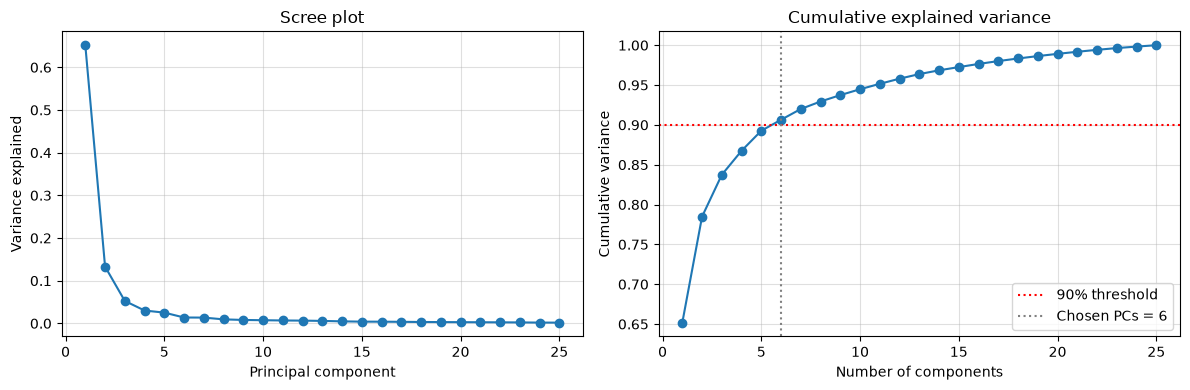

In [ ]:
components = np.arange(1, len(explained) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Left: scree plot (variance explained by each PC). Looking for where the curve flattens.
axes[0].plot(components, explained, marker="o")
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="Variance explained")
# Right: cumulative variance with the 90% threshold and the chosen number of PCs marked 
axes[1].plot(components, cumulative, marker="o")
axes[1].axhline(0.90, color="red", ls=":", label="90% threshold")
axes[1].axvline(n_components, color="gray", ls=":", label=f"Chosen PCs = {n_components}")
axes[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative variance")
axes[1].legend()
for a in axes: a.grid(alpha=0.4)
plt.tight_layout(); plt.show()

In [ ]:
# Represent each day by its scores on the chosen principal components.
# Re-fit PCA keeping only the chosen number of components and project every day onto them.
# Each trading day is now described by 6 numbers instead of 25 returns.
pca = PCA(n_components=n_components)
scores = pca.fit_transform(X)
pc_cols = [f"PC{i}" for i in range(1, n_components + 1)]
pc_scores = pd.DataFrame(scores, columns=pc_cols, index=dates) # This table is the input to (b) and (c)
display(pc_scores.head(20))

,PC1,PC2,PC3,PC4,PC5,PC6
Date,,,,,,
1926-07-01,0.147804,-0.500030,0.740417,0.203009,0.323630,0.928243
1926-07-02,0.640377,0.210350,-0.631616,1.456718,1.295260,-1.536060
1926-07-06,0.488396,0.185949,-0.479472,-0.453191,0.154566,-0.713260
1926-07-07,-0.425375,-0.894778,-1.255452,-0.179676,-0.105771,1.555379
1926-07-08,0.503189,0.265711,-0.925185,0.543001,0.998305,-0.914831
1926-07-09,-1.645876,1.902472,0.788244,-1.062659,-1.667565,0.389809
1926-07-10,1.220742,-0.434880,-1.427067,-0.784138,0.433714,-0.144875
1926-07-12,0.589481,0.210954,0.323421,-0.030299,-0.911247,-0.023185
1926-07-13,0.910687,-0.690586,0.699492,0.712619,0.935837,-0.746132


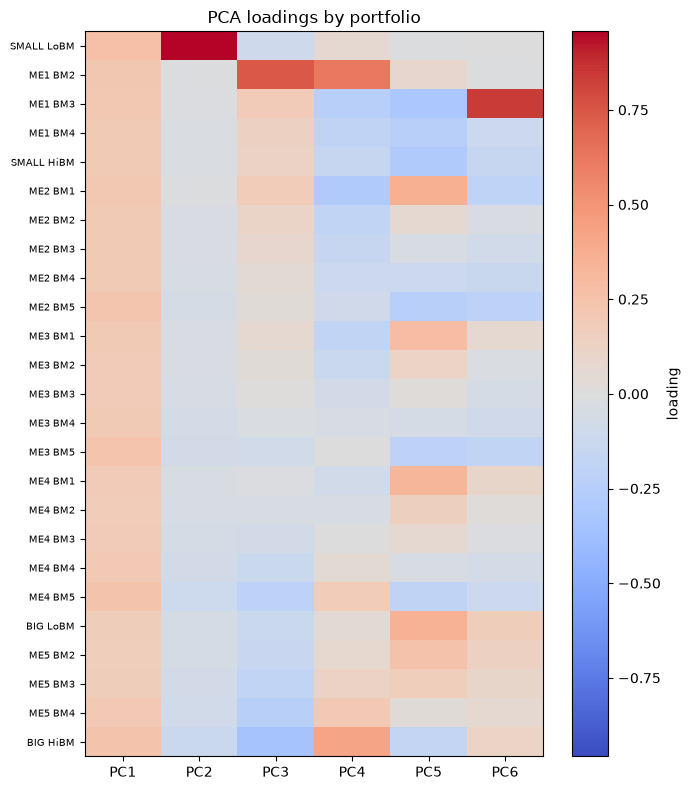

In [ ]:
# Loadings: how strongly each portfolio contributes to each PC (helps interpret the PCs)
# Rows = the 25 portfolios, columns = PCs. pca.components_ has one row per PC, so take the transpose.
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=pc_cols)

# Heatmap with a symmetric color scale (vmin = -vmax) so that 0 is the gray color
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(loadings, aspect="auto", cmap="coolwarm", vmin=-loadings.abs().max().max(), vmax=loadings.abs().max().max())
ax.set_xticks(range(n_components)); ax.set_xticklabels(pc_cols)
ax.set_yticks(range(len(loadings))); ax.set_yticklabels(loadings.index, fontsize=7)
ax.set_title("PCA loadings by portfolio"); fig.colorbar(im, label="loading"); plt.tight_layout(); plt.show()

**Interpreting the PCs:** a PC whose loadings all share a sign is a market-wide factor. PCs whose loadings change sign across portfolio groups are spreads such as small-vs-large or value-vs-growth. The first pricipal compoenent shares the same sign for all loadings and almost all look around the same value except for all of the BM5 and Small LoBM and big HiBM portfolios which have a larger positive score. So this first principal compoenent is a market wide factor. The second principal component has the largest loading value in Small LoBM and all other loadings are near 0. The rest of the principal compoenents seem to be evenly distributed amongst positive and negative signed loadings. So the rest of these PCs are spreads that affect some portfolios more than others.

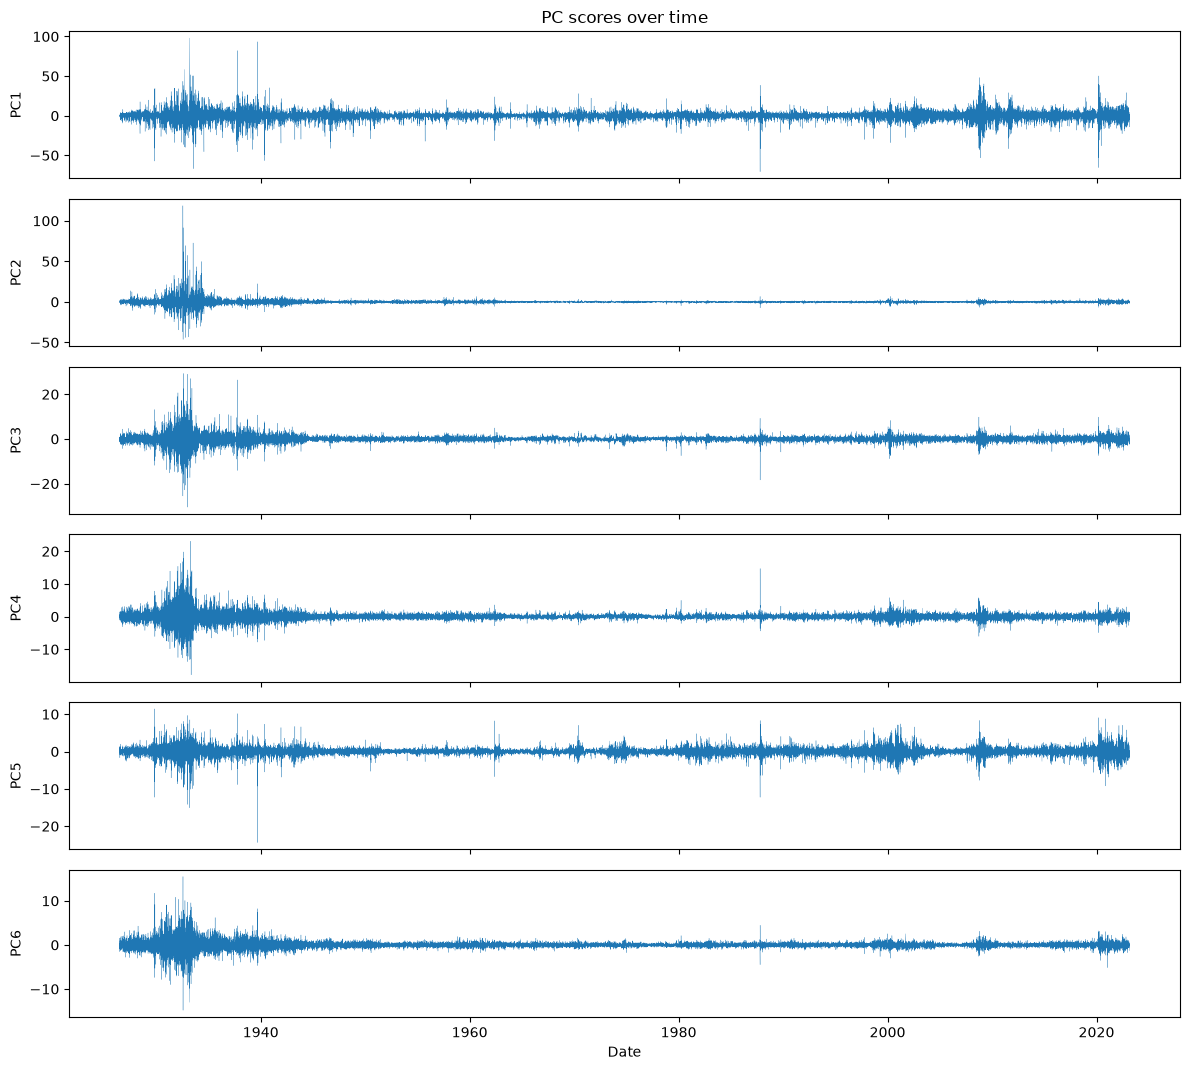

In [ ]:
# Plot each PC score through time (one stacked panel per PC with a shared x-axis). Thin lines because there are ~25,000 daily points.
fig, axes = plt.subplots(n_components, 1, figsize=(12, 1.8 * n_components), sharex=True)
axes = np.atleast_1d(axes)
for ax, pc in zip(axes, pc_cols):
    ax.plot(pc_scores.index, pc_scores[pc], lw=0.2)
    ax.set_ylabel(pc)
axes[0].set_title("PC scores over time")
axes[-1].set_xlabel("Date")
plt.tight_layout(); plt.show()

**Reading the PC score plot:** the PC scores show periods of much larger swings (very large in the early 1930s, and visibly larger around 2008-09 and 2020) separated by long calm stretches, which is the volatility clustering in stock returns that the clustering analysis picks up below. PC2 is almost entirely active in the 1930s, so that PC mainly describes that one era.

## Helper methods shared by (b), (c), and (d)

Cluster ids are arbitrary, so I relabel them by volatility of the market proxy (0 = calmest day type, highest id = most volatile). This keeps colors and names consistent across methods.

In [8]:
# Relabel the names of the clusters by the volatility of the cluster
def relabel_by_vol(labels):
    vol = pd.Series(market.to_numpy()).groupby(labels).std().sort_values()
    mapping = {old: new for new, old in enumerate(vol.index)}
    return np.array([mapping[l] for l in labels])

def profile(labels):
    df = pd.DataFrame({"cluster": labels, "market": market.to_numpy()})
    g = df.groupby("cluster")["market"]
    return pd.DataFrame({"days": g.size(), "share": g.size() / len(df),
                         "mean_return": g.mean(), "return_std": g.std()}).round(4)

def scatter_pairs(labels, centers=None, title=""):
    pairs = [(0, 1), (0, 2), (1, 2)] if n_components >= 3 else [(0, 1)]
    fig, axes = plt.subplots(1, len(pairs), figsize=(5.5 * len(pairs), 5))
    axes = np.atleast_1d(axes)
    for ax, (i, j) in zip(axes, pairs):
        for c in np.unique(labels):
            m = labels == c
            ax.scatter(pc_scores.iloc[m, i], pc_scores.iloc[m, j], s=5, alpha=.4, color=PALETTE[c], label=f"Cluster {c}")
        if centers is not None:
            ax.scatter(centers[:, i], centers[:, j], marker="X", s=160, color="black", edgecolor="white", label="Centroids")
        ax.set(xlabel=pc_cols[i], ylabel=pc_cols[j]); ax.grid(alpha=.3)
    axes[0].legend(markerscale=2, fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()

def monthly_share(labels, k):
    df = pd.DataFrame({"cluster": labels}, index=dates.to_numpy())
    s = pd.crosstab(df.index.to_period("M"), df["cluster"], normalize="index")
    return s.reindex(columns=range(k), fill_value=0)

def plot_monthly_share(share, title):
    s = share.copy(); s.index = s.index.to_timestamp()
    ax = s.plot.area(figsize=(13, 4), color=[PALETTE[c] for c in s.columns], linewidth=0)
    ax.set(title=title, xlabel="Date", ylabel="Share of trading days", ylim=(0, 1))
    ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

### (b) Hierarchical Clustering Analysis on PCA Results
**Settings:**
- Features: The 6 principal component scores chosen above, noise in the low variance PCs is discarded.
- Distance: Euclidean is the most natural method to use for PCs.
- Linkage: I compare ward, complete, and average linkage using cophenetic correlation (how faithfully the tree distances reflect the original pairwise distances). This is done on a random sample because the full data has too many days for a dendrogram or pairwise distance matrix.
- Number of clusters: chosen by considering the silhouette score on the same sample. 

Cophenetic correlation by linkage: {'ward': np.float64(0.556), 'complete': np.float64(0.647), 'average': np.float64(0.892)}


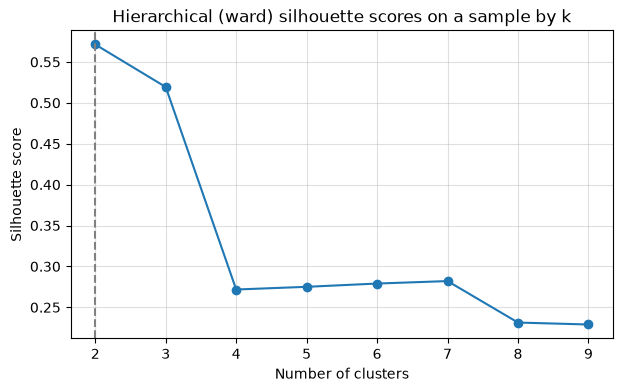

Highest silhouette score in this range: k=2


In [ ]:
# Reproducible sample for comparing clusters and drawing the dendrogram
sample = pc_scores.sample(n=min(5000, len(pc_scores)), random_state=SEED)
orig_dist = pdist(sample.to_numpy())

coph = {}
# Cophenetic correlation: how well the tree's distances match the original distances
for method in ["ward", "complete", "average"]:
    coph[method] = cophenet(linkage(sample.to_numpy(), method=method), orig_dist)[0]
print("Cophenetic correlation by linkage:", {k: round(v, 3) for k, v in coph.items()})

# Choose the number of clusters: silhouette score (higher = tighter, better separated clusters)
k_vals = range(2, 10) # Compare silhouette scores for different cluster counts
sil_h = [silhouette_score(sample, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(sample)) for k in k_vals]
best_k_h = k_vals[int(np.argmax(sil_h))]

# Plot silhouette vs k and mark the best k
plt.figure(figsize=(7, 4))
plt.plot(list(k_vals), sil_h, marker="o")
plt.axvline(best_k_h, color="gray", ls="--")
plt.xlabel("Number of clusters"); plt.ylabel("Silhouette score")
plt.title("Hierarchical (ward) silhouette scores on a sample by k")
plt.grid(alpha=0.4); plt.show()

print(f"Highest silhouette score in this range: k={best_k_h}")

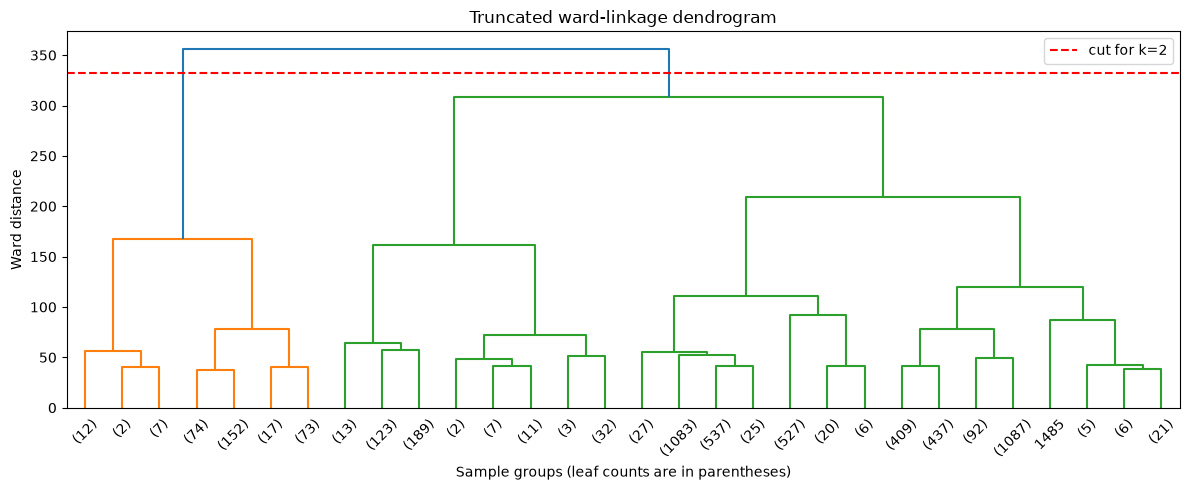

In [10]:
Z = linkage(sample.to_numpy(), method="ward", metric="euclidean")
cut = (Z[-(best_k_h - 1), 2] + Z[-best_k_h, 2]) / 2
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=cut)
plt.axhline(cut, color="red", ls="--", label=f"cut for k={best_k_h}")
plt.xlabel("Sample groups (leaf counts are in parentheses)")
plt.ylabel("Ward distance")
plt.title("Truncated ward-linkage dendrogram"); plt.legend()
plt.tight_layout(); plt.show()

,days,share,mean_return,return_std
cluster,,,,
0,23188,0.9115,0.2678,0.8938
1,2250,0.0885,-2.1915,1.3165


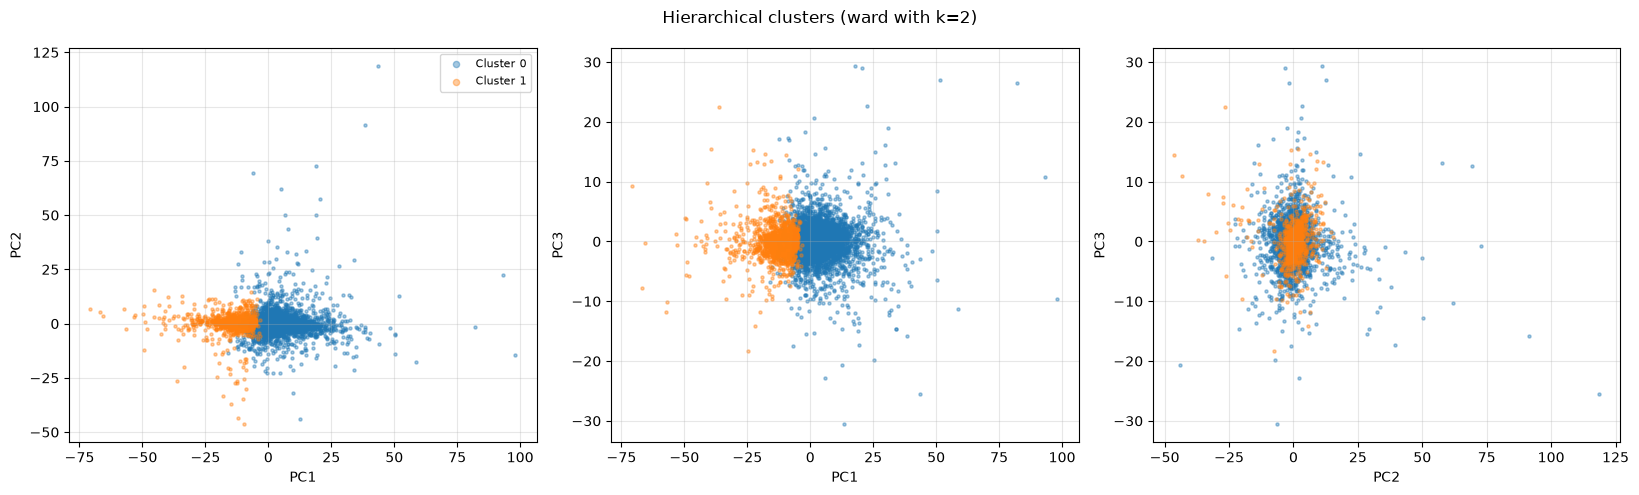

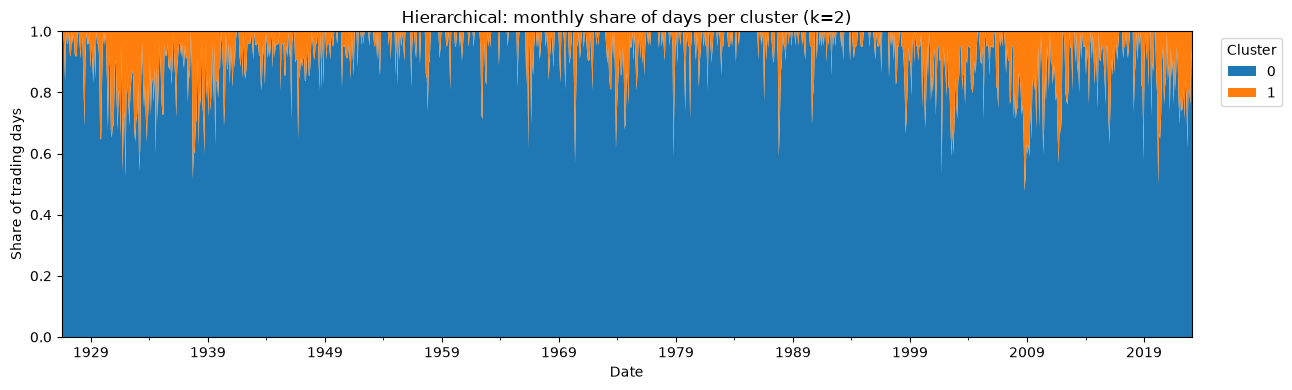

In [ ]:
# Fit the final hierarchical model on ALL days (not just the sample) using the chosen settings,
# then relabel clusters from calmest to most volatile.
hier_labels = relabel_by_vol(AgglomerativeClustering(n_clusters=best_k_h, linkage="ward").fit_predict(pc_scores))

display(profile(hier_labels))
scatter_pairs(hier_labels, title=f"Hierarchical clusters (ward with k={best_k_h})")
plot_monthly_share(monthly_share(hier_labels, best_k_h), f"Hierarchical: monthly share of days per cluster (k={best_k_h})")

**Results (b):**
- **Linkage choice.** Cophenetic correlation was 0.556 (ward), 0.647 (complete) and 0.892 (average). Average linkage reproduces the original distances best, but I used **ward** for the final model. Average linkage on data with a dense core and a long tail of extreme days tends to leave a few outlier days in tiny clusters and lump everything else together, which is not useful for describing day types. Ward minimizes within-cluster variance and, like K-Means, gives compact clusters of useful size. The cophenetic correlation of ward is the lowest, which is a limitation of my choice.
- **Number of clusters.** The silhouette score on the sample was highest for **k = 2**, so the final model has two clusters.
- **Clusters found.** Cluster 0 (91.2% of days) is the ordinary day type: average market return +0.27% and daily standard deviation 0.89%. Cluster 1 (8.8% of days) is the turbulent day type: average market return -2.19% and standard deviation 1.32%. In other words, the hierarchical clustering mostly separates large-drop days from everything else.
- **Over time.** The monthly share plot shows cluster 1 concentrated in the 1930s, around 2000-2002, 2008-09 and 2020, and rare in calm decades such as the 1950s to 1960s.

### (c) K-Means Clustering on the PC Scores
**Settings:**
- **Features:** Same 6 PC scores. K-Means minimizes the within-cluster squred Euclidean distance, which fits the PC scores.
- **Initialization:** `n_init=20` random restarts and keep the best, K-Means can land in poor local optima.
- **k:** elbow plot and silhouette score on the sample help to decide k. The elbow is a sanity check while the silhouette score picks the k value.

In [ ]:
# Choose k for K-Means using the same 5,000-day sample.
# inertia = within-cluster sum of squared distances (for the elbow plot, k = 1..10)
# silhouette is only defined for k >= 2
inertias, sil_k = [], []
for k in range(1, 11):
    # n_init=20, run 20 random initializations and keep the best to avoid a poor local optima
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(sample)
    inertias.append(km.inertia_)
    if k >= 2:
        sil_k.append(silhouette_score(sample, km.labels_))
k_range = list(range(2, 11))
best_k_km = k_range[int(np.argmax(sil_k))] # k with the highest silhouette score

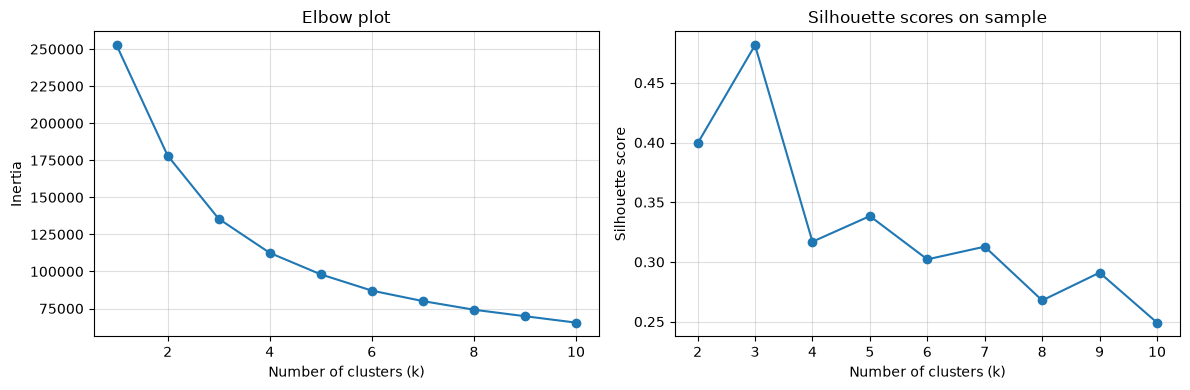

Highest silhouette score in this range: k=3


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Left: elbow plot (inertia vs k); the "bend" suggests where extra clusters stop helping much
axes[0].plot(range(1, 11), inertias, marker="o")
axes[0].set(title="Elbow plot", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[0].grid(alpha=0.4)
# Right: silhouette score vs k; the peak is the k we use
axes[1].plot(k_range, sil_k, marker="o")
axes[1].set(title="Silhouette scores on sample", xlabel="Number of clusters (k)", ylabel="Silhouette score")
axes[1].grid(alpha=0.4)
plt.tight_layout(); plt.show()

print(f"Highest silhouette score in this range: k={best_k_km}")

,days,share,mean_return,return_std
cluster,,,,
0,19087,0.7503,0.1109,0.4410
1,3518,0.1383,-1.7826,1.1939
2,2833,0.1114,1.9178,1.2366


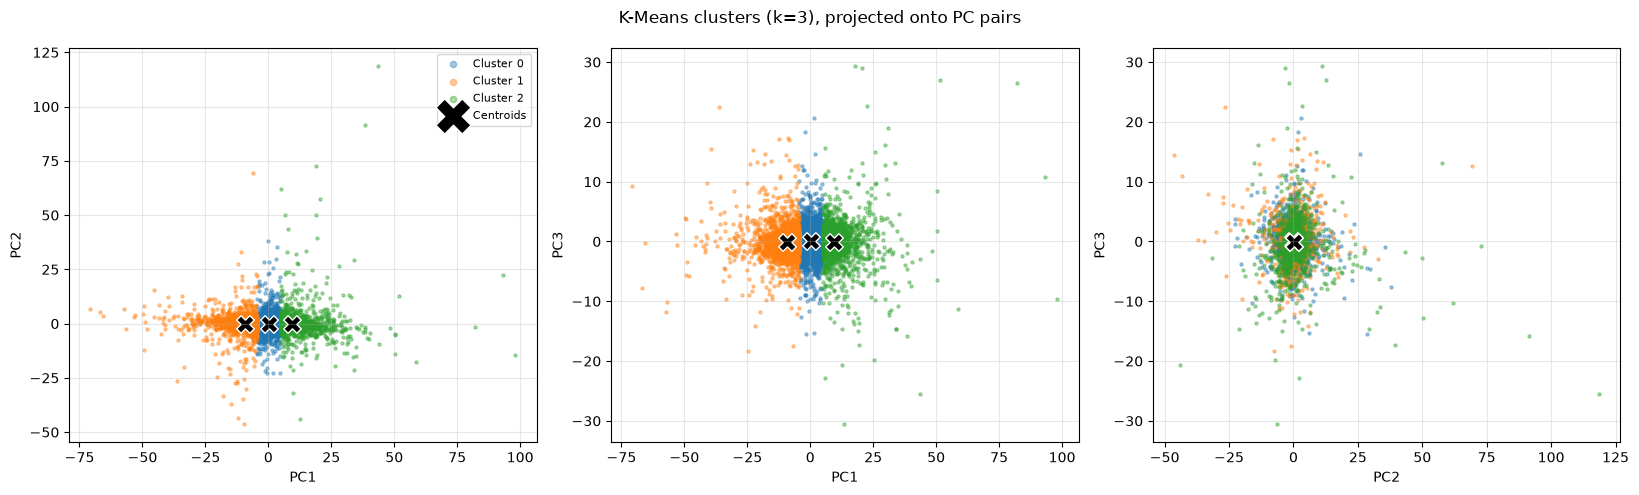

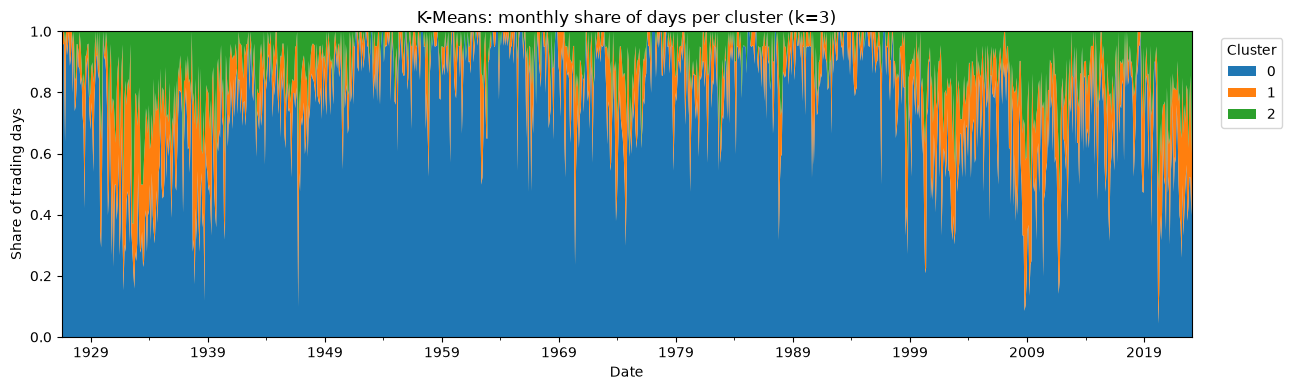

Agreement between hierarchical and K-Means labels (adjusted rand index): 0.397


In [ ]:
# Fit the final K-Means model on all days with the chosen k
kmeans = KMeans(n_clusters=best_k_km, n_init=20, random_state=SEED).fit(pc_scores)
km_labels = relabel_by_vol(kmeans.labels_)
# Reorder the centroids so row i is the centroid of the relabeled cluster i
order = pd.Series(market.to_numpy()).groupby(kmeans.labels_).std().sort_values().index
centers = kmeans.cluster_centers_[list(order)]

display(profile(km_labels)) # Size and market-return stats per cluster
scatter_pairs(km_labels, centers=centers, title=f"K-Means clusters (k={best_k_km}), projected onto PC pairs")
plot_monthly_share(monthly_share(km_labels, best_k_km), f"K-Means: monthly share of days per cluster (k={best_k_km})")
# Adjusted Rand Index: agreement between the two clusterings (0 = chance, 1 = identical)
print("Agreement between hierarchical and K-Means labels (adjusted rand index):", round(adjusted_rand_score(hier_labels, km_labels), 3))

**Results (c):**
- **k.** The silhouette score on the sample was highest for **k = 3**, with a clear peak (about 0.48 versus 0.40 at k = 2 and 0.32 at k = 4). The elbow plot only bends gradually, so it does not point to one clear k and was used as a sanity check.
- **Clusters found.** Cluster 0 (75.0% of days) is a calm day type, with average return +0.11% and standard deviation 0.44%. Cluster 1 (13.8%) is a turbulent down type, with average return -1.78% and standard deviation 1.19%. Cluster 2 (11.1%) is a turbulent up type, with average return +1.92% and standard deviation 1.24%. K-Means therefore splits the volatile days by direction, which hierarchical clustering with k = 2 does not do.
- **Comparison with hierarchical.** The adjusted Rand index between the two clusterings is 0.397 (see the discussion below).

**Discussion (c):** The first two principal components separate the cluster centroids well in just two dimensions. The second and third PCs overlap very heavily in two dimensions but there are 6 PCs and so the clusters are in 6 dimensions, them not being well separated in 2 dimensions does not mean they are overlapping in the others. The adjusted random index, or agreement between the two clustering methods is around 0.397. This is better than chance which would give a value of 0.0 but not too close to agreeing entirely which would give a value of around 1.0. So the clusters agree a slight amount but they are not overall well connected. 

### (d) Can the Clusters Predict the NBER Recession Index?
**Conceptual issue:** clustering is unsupervised. It never sees USREC, so cluster labels have no built-in link to recessions. They *can* still be used as features if the day-type mix in a month differs between recession and expansion months. I test that directly, using K-means shares (the same would work for hierarchical):

1. Compare the average cluster mix in recession vs. non-recession months.
2. Check timing with a lead/lag correlation: do clusters move *before* recessions or only alongside them?
3. Fit a simple classifier on monthly cluster shares with a chronological train/test split (no shuffling, to avoid using the future to predict the past) and report AUC against the 0.5 baseline.

In [ ]:
# Load the NBER recession indicator for each month (1=recession, 0=no recession)
usrec = pd.read_csv("HW5USREC.csv", parse_dates=["observation_date"])
rec = usrec.assign(month=usrec["observation_date"].dt.to_period("M")).set_index("month")["USREC"]

# Monthly mix of K-Means day types, and the matching recession flag for each of those months
shares = monthly_share(km_labels, best_k_km)
missing = shares.index.difference(rec.index)
if len(missing): raise ValueError(f"USREC is missing {len(missing)} portfolio months") # Check that dates line up
y_m = rec.reindex(shares.index).astype(int)
print(f"{len(y_m)} months | {y_m.mean():.1%} are NBER recession months (the no-skill baseline)")

# 1. Average cluster mix: recession vs. expansion months
display(shares.groupby(y_m).mean().rename(index={0: "Expansion", 1: "Recession"}).round(3))

1160 months | 17.3% are NBER recession months (the no-skill baseline)


cluster,0,1,2
USREC,,,
Expansion,0.776,0.123,0.101
Recession,0.648,0.203,0.150


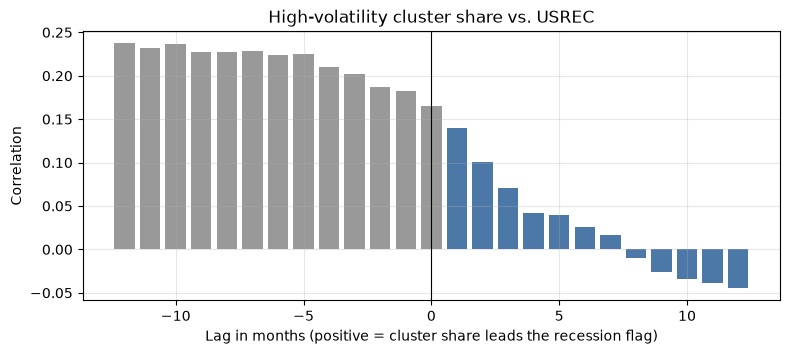

Correlation at lag 0: 0.165 | best lead (lag>0): 1 -> 0.14


In [ ]:
# 2. Timing: correlation between the high-volatility cluster share and USREC at different lags.
#    Positive lag = share from `lag` months EARLIER vs. today's recession flag (a leading signal).
high = shares[best_k_km - 1] # Share of days in the most volatile cluster
lags = list(range(-12, 13))
xc = [y_m.corr(high.shift(l)) for l in lags]
plt.figure(figsize=(9, 3.5))
plt.bar(lags, xc, color=["#4C78A8" if l > 0 else "#999999" for l in lags])
plt.axvline(0, color="k", lw=.8)
plt.xlabel("Lag in months (positive = cluster share leads the recession flag)")
plt.ylabel("Correlation"); plt.title("High-volatility cluster share vs. USREC"); plt.grid(alpha=.3); plt.show()
print("Correlation at lag 0:", round(xc[lags.index(0)], 3), "| best lead (lag>0):",
      lags[int(np.argmax(xc[13:])) + 13], "->", round(max(xc[13:]), 3))

Train: 1926-07..1994-02 | Test: 1994-03..2023-02 (test recession rate 8.0%)
Chronological hold-out AUC: 0.812
Confusion matrix at 0.5 (rows = actual, cols = predicted):
 [[144 176]
 [  2  26]]
Expanding-window AUCs: [0.482 0.656 0.703 0.708 0.857]


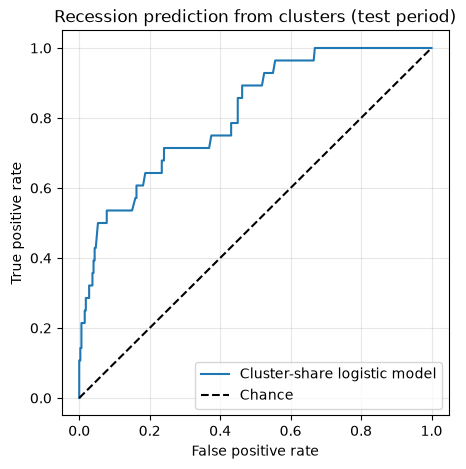

In [ ]:
# 3. Classifier on cluster shares. Shares sum to 1, so drop one column to avoid perfect collinearity.
F = shares.iloc[:, 1:]
# Chronological split: first 70% of months for training, last 30% for testing (no shuffling,
# so the model never sees the future when predicting the past)
split = int(len(F) * 0.7)
Xtr, Xte, ytr, yte = F.iloc[:split], F.iloc[split:], y_m.iloc[:split], y_m.iloc[split:]
# class_weight="balanced" compensates for recessions being rare (~17% of months)
clf = LogisticRegression(class_weight="balanced", max_iter=1000).fit(Xtr, ytr)
p = clf.predict_proba(Xte)[:, 1] # predicted probability of recession for each test month
print(f"Train: {Xtr.index[0]}..{Xtr.index[-1]} | Test: {Xte.index[0]}..{Xte.index[-1]} "
      f"(test recession rate {yte.mean():.1%})")
print(f"Chronological hold-out AUC: {roc_auc_score(yte, p):.3f}")
print("Confusion matrix at 0.5 (rows = actual, cols = predicted):\n", confusion_matrix(yte, p > 0.5))

# Expanding-window check, train on the past, test on the next block, repeated 5 times.
# Gives a sense of how stable the AUC is across eras. Skip folds with only one class (AUC undefined)
aucs = []
for tr, te in TimeSeriesSplit(n_splits=5).split(F):
    if y_m.iloc[te].nunique() == 2:
        m = LogisticRegression(class_weight="balanced", max_iter=1000).fit(F.iloc[tr], y_m.iloc[tr])
        aucs.append(roc_auc_score(y_m.iloc[te], m.predict_proba(F.iloc[te])[:, 1]))
print("Expanding-window AUCs:", np.round(aucs, 3))

# ROC curve on the hold-out period (dashed diagonal = random guessing)
fpr, tpr, _ = roc_curve(yte, p)
plt.figure(figsize=(5, 5)); plt.plot(fpr, tpr, label="Cluster-share logistic model"); plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("Recession prediction from clusters (test period)")
plt.legend(); plt.grid(alpha=.3); plt.show()

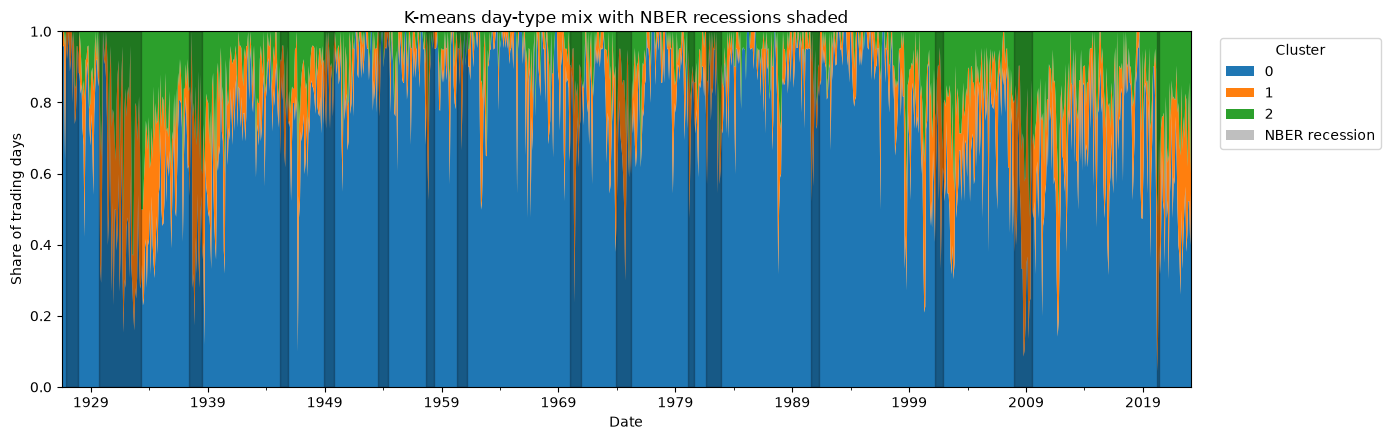

In [ ]:
# Cluster composition with NBER recessions shaded
is_rec = y_m.eq(1)
starts = is_rec & ~is_rec.shift(1, fill_value=False) # First month of each recession
ends = is_rec & ~is_rec.shift(-1, fill_value=False) # Last month of each recession 

s = shares.copy(); s.index = s.index.to_timestamp()
fig, ax = plt.subplots(figsize=(14, 4.5))
s.plot.area(ax=ax, color=[PALETTE[c] for c in s.columns], linewidth=0)
# Shade each recession from its first month to the end of its last month
for a, b in zip(y_m.index[starts], y_m.index[ends]):
    ax.axvspan(a.to_timestamp(), (b + 1).to_timestamp(), color="black", alpha=0.25, zorder=10)
handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="black", alpha=0.25)); labels.append("NBER recession")
ax.legend(handles, labels, title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set(title="K-means day-type mix with NBER recessions shaded", xlabel="Date", ylabel="Share of trading days", ylim=(0, 1))
plt.tight_layout(); plt.show()

**Results (d):**
- **Cluster mix in recession vs. expansion months.** In expansion months, 77.6% of days are calm, 12.3% are turbulent-down and 10.1% are turbulent-up. In recession months the calm share falls to 64.8% while turbulent-down rises to 20.3% and turbulent-up to 15.0%. Recessions therefore have more of *both* kinds of turbulent days, i.e. more volatility rather than just more losses.
- **Timing.** The correlation between the turbulent-down share and USREC is 0.165 at lag 0 and 0.14 at a one-month lead, which is weak and mostly contemporaneous. There is no strong sign that the cluster mix moves well ahead of recessions.
- **Classifier.** A logistic regression on the monthly cluster shares, trained on 1926-07 to 1994-02 and tested on 1994-03 to 2023-02 (8.0% recession months), gets a hold-out AUC of 0.812 against 0.5 for chance. At a 0.5 threshold it catches 26 of 28 recession months but also flags 176 of 320 expansion months, so only about 13% of its recession alarms are right (26 of 202), compared with the 8% base rate. The expanding-window AUCs are 0.482, 0.656, 0.703, 0.708 and 0.857, so the signal is unstable across eras and absent in the earliest fold. The shaded plot agrees: the turbulent clusters (orange and green) swell during the Great Depression, 2008-09 and 2020 recessions, but they also swell in non-recession periods such as 2000 and 2011, and many recessions (for example in the 1950s and 1970s) show little change in the mix.

### Answer to (d)
**Short answer:** the clusters cannot predict recessions on their own, but they may carry partial information.
* **Why not on their own:** clustering is unsupervised and groups days by return behaviour (mostly volatility), not by the economic cycle. USREC is also determined retroactively by the NBER, so it is not a daily market outcome.
* **What the evidence shows:** compare the recession vs. expansion cluster mix table, the lead/lag plot (is the relationship contemporaneous or leading?), and the hold-out AUC relative to 0.5, along with the recession base rate. Note that high-volatility episodes also occur outside recessions, which limits precision (see the confusion matrix).
* **Caveats:** only about a dozen distinct recessions, so test-period AUC is noisy; results depend on the chosen k and split date.

## Conclusion
- **(a) PCA:** 6 principal components keep about 90.6% of the variance. PC1 is a market-wide factor (about 65% of variance) and the others are spread factors across portfolios.
- **(b) Hierarchical:** ward linkage on the 6 PC scores with k = 2 (chosen by silhouette) separates the 91% ordinary days from 9% turbulent, mostly negative-return days.
- **(c) K-Means:** k = 3 (chosen by silhouette) gives calm days (75%), turbulent-down days (14%) and turbulent-up days (11%). The two clusterings only partly agree (adjusted Rand index 0.40), because they split the data along different lines.
- **(d) Recessions:** the clusters are not a recession predictor by themselves. They measure market volatility, and recessions have more volatile days but so do many expansion months. Used as monthly features, they give a better-than-chance but unstable and imprecise signal, and one that is largely contemporaneous rather than leading.

**Limitations.** Silhouette scores for hierarchical clustering were computed on a 5,000-day sample, the ward linkage has the lowest cophenetic correlation of the three methods tried, only about a dozen recessions are available for evaluation, and the choices of k and of the train/test split date affect the results.